# **[실습] RNN - LSTM 날씨 예측**
* https://data.kma.go.kr/stcs/grnd/grndTaList.do?pgmNo=70
* seoul_temp_sample.csv

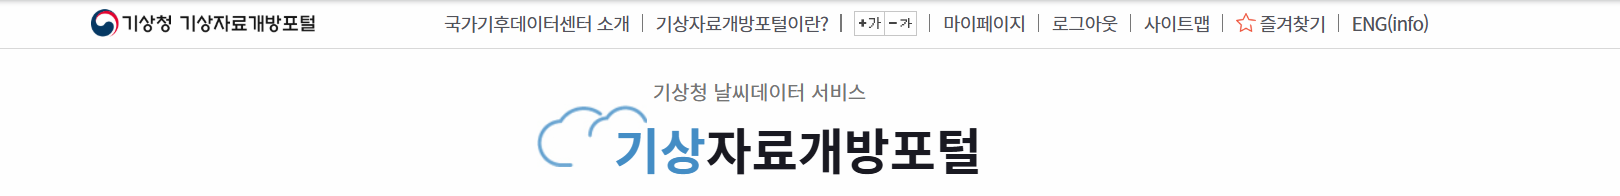

In [1]:
import os
# TensorFlow 안내 및 경고 로그 끄기 (3 = ERROR/FATAL 로그만 표시)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
# oneDNN 최적화 관련 안내 문구 숨기기
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
# absl 라이브러리 초기화 전 경고(WARNING: All log messages...) 숨기기
os.environ['ABSL_LOGGING_MIN_LOG_LEVEL'] = '3'

import warnings
warnings.filterwarnings(action='ignore')

from sklearn import set_config
set_config(display="text")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

import tensorflow as tf
tf.random.set_seed(1234)
np.random.seed(1234)

from sklearn.model_selection import train_test_split   #---- 문제답 분리

from keras.models import Sequential
#from keras.layers import Conv2D, MaxPooling2D  #---- CNN
from tensorflow.keras.layers import SimpleRNN , LSTM, Input, Reshape  #-----RNN
from keras.layers import Dense, Flatten                      #---- FC

#---------------------- 한글 폰트 지정 -----------------------
plt.rcParams["axes.unicode_minus"] = False                   # 마이너스 기호 깨짐 방지

#plt.rcParams["font.family"] = "Malgun Gothic"               #--------------윈도우 인 경우 
import matplotlib.font_manager as fm                         #--------------리눅스인 경우
font_path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
fm.fontManager.addfont(font_path)
font_prop = fm.FontProperties(fname=font_path)
plt.rcParams["font.family"] = font_prop.get_name()

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error

# **Data Load**

In [2]:
df = pd.read_csv("../datas/seoul_temp_sample.csv", parse_dates=['rdate'])

In [3]:
df = df.set_index('rdate')
df.head(1)

,atemp,ltemp,htemp
rdate,,,
2026-01-01,-7.4,-10.5,-2.1


# ----------------------------

# **Feature_dim:3 , 5일예측**

## **공통함수**

In [4]:
                                                           #---★5일치예측
def MY_WINDOW_SLIDING(data,  window_size=5, feature_dim=1, pred_size=5) :
    data_size = len(data)                #---★5일치예측  
    loop_cnt = data_size - window_size - pred_size + 1
    
    X_list = []
    y_list = []
    for i in range(loop_cnt ) : 
        X_list.append( data[i : i+window_size] )
        y_list.append( data[i+window_size : i+window_size+pred_size]     )
                                                          #---★5일치예측
    X = np.array(X_list).reshape(-1, window_size, feature_dim)
    y = np.array(y_list)
    #print(X)
    #print(y)
    return X, y

In [5]:
X3,y3 = MY_WINDOW_SLIDING(df.values,  window_size=5, feature_dim=3, pred_size=5)
X3.shape, y3.shape                                                #---★5일치예측

((264, 5, 3), (264, 5, 3))

## **LSTM 모델 구축**

In [6]:
model = Sequential([
    LSTM(8,  return_sequences=True, activation='tanh', input_shape=(5,3) ) ,
    LSTM(16, return_sequences=True, activation='tanh') ,
    LSTM(4, activation='tanh') ,
    Dense(15),      #---★5일치3개피쳐
    Reshape((5,3))  #---★5일치예측  
])
model.compile(loss='mse', optimizer='adam', metrics=[tf.keras.metrics.RootMeanSquaredError(name='rmse')])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 5, 8)           │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 5, 16)          │         1,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 4)              │           336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 15)             │            75 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 5, 3)           │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,395 (9.36 KB)

 Trainable params: 2,395 (9.36 KB)

 Non-trainable params: 0 (0.00 B)

## **전처리 & 가공**
* 스케일링
* X:(268, 5, 3), y:(268, 3)

In [7]:
X_scaler = StandardScaler()
y_scaler = StandardScaler()

X3_scale = X_scaler.fit_transform(X3.reshape(-1, 3))   #--------오직 2차만 학습가능 (3D --> 2D로 잠시 바꿔 스케일링)
y3_scale = y_scaler.fit_transform(y3.reshape(-1, 3)) 
print(X3_scale.shape, y3_scale.shape )

X3_scale =  X3_scale.reshape(-1, 5,3)   #---★5일치예측   
y3_scale =  y3_scale.reshape(-1, 5,3)   #---★5일치예측    
print(X3_scale.shape, y3_scale.shape )

(1320, 3) (1320, 3)
(264, 5, 3) (264, 5, 3)


In [8]:
X3_scale[:1], y3_scale[:1]

(array([[[-2.12165018, -1.9525806 , -2.10079801],
         [-2.17591058, -2.03153774, -2.25504657],
         [-1.87747838, -1.8911695 , -1.91025567],
         [-1.43435177, -1.26828547, -1.45658344],
         [-1.62426317, -1.43497275, -1.74693367]]]),
 array([[[-1.61672053, -1.72614351, -1.6449483 ],
         [-1.55175585, -1.57347114, -1.71957476],
         [-2.0065086 , -1.83391225, -2.11136373],
         [-1.56103652, -1.69920133, -1.57965013],
         [-1.34758115, -1.51958677, -1.31845749]]]))

## train(8:2) / test 분리

In [9]:
X3_train = X3_scale[ : -1]
y3_train = y3_scale[ : -1]

X3_test  = X3_scale[-1 : ]
y3_test  = y3_scale[-1 : ]

print(len(X3_train) , len(X3_test),  len(y3_train), len(y3_test))

263 1 263 1


In [10]:
X3_train.shape , X3_test.shape,  y3_train.shape, y3_test.shape

((263, 5, 3), (1, 5, 3), (263, 5, 3), (1, 5, 3))

In [11]:
X8,X2,y8,y2 = train_test_split(X3_train,y3_train, test_size=0.2, shuffle=False)

In [12]:
X8.shape, y8.shape, X2.shape, y2.shape

((210, 5, 3), (210, 5, 3), (53, 5, 3), (53, 5, 3))

## 모델 생성 & 학습

In [13]:
fit_res = model.fit(X8, y8, epochs=50, batch_size=10, validation_data=(X2, y2))

Epoch 1/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - loss: 1.0656 - rmse: 1.0323 - val_loss: 0.7185 - val_rmse: 0.8477
Epoch 2/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 1.0366 - rmse: 1.0181 - val_loss: 0.7115 - val_rmse: 0.8435
Epoch 3/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.9852 - rmse: 0.9926 - val_loss: 0.6814 - val_rmse: 0.8255
Epoch 4/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.8987 - rmse: 0.9480 - val_loss: 0.6276 - val_rmse: 0.7922
Epoch 5/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.7903 - rmse: 0.8890 - val_loss: 0.5583 - val_rmse: 0.7472
Epoch 6/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6898 - rmse: 0.8305 - val_loss: 0.4841 - val_rmse: 0.6958
Epoch 7/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6038 - rmse: 0.7770 - val_loss: 0.4156 - val_rmse: 0.6447
Epoch 8/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5302 - rmse: 0.7282 - val_loss: 0.3571 - val_rmse: 0.5976
Epoch 9/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - los

## 평가 시각화

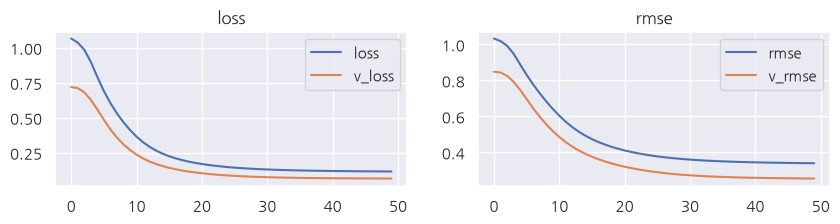

In [14]:
plt.figure(figsize=(10,2))
ax1 = plt.subplot(1,2,1)
ax1.plot(fit_res.history['loss']   ,   label="loss")
ax1.plot(fit_res.history['val_loss'],  label="v_loss")
ax1.legend()
ax1.set_title("loss")

ax2 = plt.subplot(1,2,2)
ax2.plot(fit_res.history['rmse']   ,   label="rmse")
ax2.plot(fit_res.history['val_rmse'],  label="v_rmse")
ax2.legend()
ax2.set_title("rmse")

plt.show()

## test 예측

In [15]:
pred = model.predict(X3_test)
print(pred)
print(y3_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step
[[[0.55763704 0.5280492  0.55197126]
  [0.47737968 0.49222618 0.52492636]
  [0.4765128  0.6075849  0.57560414]
  [0.60481584 0.55646515 0.5944885 ]
  [0.51710415 0.5389553  0.59178567]]]
[[[0.49927183 0.5369999  0.55653255]
  [0.54567517 0.46515408 0.67780056]
  [0.43430715 0.54598063 0.43526454]
  [0.40646515 0.20471297 0.57518917]
  [0.47142982 0.39330825 0.59384578]]]


In [16]:
                                     #---★5일치예측  
pred    = y_scaler.inverse_transform(pred.reshape(-1,3))       #-------2D : 스케일링 된 예측값 점수 내기전 원복
y3_test = y_scaler.inverse_transform(y3_test.reshape(-1,3))    #-------2D : 스케일링 된 정답값 점수 내기전 원복

In [17]:
print(pred)
print(y3_test)

[[22.52889  18.100334 27.451103]
 [21.664112 17.701447 27.161179]
 [21.65477  18.985962 27.704449]
 [23.037247 18.416744 27.90689 ]
 [22.092146 18.221773 27.877914]]
[[21.9 18.2 27.5]
 [22.4 17.4 28.8]
 [21.2 18.3 26.2]
 [20.9 14.5 27.7]
 [21.6 16.6 27.9]]


In [18]:
rmse = root_mean_squared_error(y3_test, pred)
print(f"RMSE : {rmse:.4f}")

RMSE : 1.3388


# ----------------------------

# **Feature_dim:3 , 1일예측**

## **공통함수**

In [19]:
def MY_WINDOW_SLIDING(data,  window_size=5, feature_dim=1) :
    data_size = len(data)
    loop_cnt = data_size - window_size
    #print("loop_cnt = data_size - window_size", loop_cnt)
    
    X_list = []
    y_list = []
    for i in range(loop_cnt ) : 
        X_list.append( data[i : i+window_size] )
        y_list.append( data[i+window_size]     )
   
    X = np.array(X_list).reshape(-1, window_size, feature_dim)
    y = np.array(y_list)
    #print(X)
    #print(y)
    return X, y

In [20]:
X3,y3 = MY_WINDOW_SLIDING(df.values,  window_size=5, feature_dim=3)
X3.shape, y3.shape

((268, 5, 3), (268, 3))

## **LSTM 모델 구축**

In [21]:
model = Sequential([
    LSTM(8,  return_sequences=True, activation='tanh', input_shape=(5,3) ) ,
    LSTM(16, return_sequences=True, activation='tanh') ,
    LSTM(4, activation='tanh') ,
    Dense(3) 
])
model.compile(loss='mse', optimizer='adam', metrics=[tf.keras.metrics.RootMeanSquaredError(name='rmse')])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_3 (LSTM)                   │ (None, 5, 8)           │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 5, 16)          │         1,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 4)              │           336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            15 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,335 (9.12 KB)

 Trainable params: 2,335 (9.12 KB)

 Non-trainable params: 0 (0.00 B)

## **전처리 & 가공**
* 스케일링
* X:(268, 5, 3), y:(268, 3)

In [22]:
X_scaler = StandardScaler()
y_scaler = StandardScaler()

X3_scale = X_scaler.fit_transform(X3.reshape(-1, 3))   #--------오직 2차만 학습가능 (3D --> 2D로 잠시 바꿔 스케일링)
y3_scale = y_scaler.fit_transform(y3.reshape(-1, 3)) 
print(X3_scale.shape, y3_scale.shape )

X3_scale =  X3_scale.reshape(-1, 5,3)  
y3_scale =  y3_scale.reshape(-1,3)   
print(X3_scale.shape, y3_scale.shape )

(1340, 3) (268, 3)
(268, 5, 3) (268, 3)


In [23]:
X3_scale[:1], y3_scale[:1]

(array([[[-2.14098453, -1.97100864, -2.11959321],
         [-2.19553726, -2.05036858, -2.27461254],
         [-1.89549722, -1.90928425, -1.92809876],
         [-1.44998321, -1.28322253, -1.47215957],
         [-1.64091778, -1.45076017, -1.76396065]]]),
 array([[-1.60159873, -1.70964486, -1.62744876]]))

## train(8:2) / test 분리

In [24]:
X3_train = X3_scale[ : -1]
y3_train = y3_scale[ : -1]

X3_test  = X3_scale[-1 : ]
y3_test  = y3_scale[-1 : ]

print(len(X3_train) , len(X3_test),  len(y3_train), len(y3_test))

267 1 267 1


In [25]:
X3_train.shape , X3_test.shape,  y3_train.shape, y3_test.shape

((267, 5, 3), (1, 5, 3), (267, 3), (1, 3))

In [26]:
X8,X2,y8,y2 = train_test_split(X3_train,y3_train, test_size=0.2, shuffle=False)

## 모델 생성 & 학습

In [27]:
fit_res = model.fit(X8, y8, epochs=50, batch_size=10, validation_data=(X2, y2))

Epoch 1/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 1.0444 - rmse: 1.0219 - val_loss: 0.6554 - val_rmse: 0.8095
Epoch 2/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.9405 - rmse: 0.9698 - val_loss: 0.6238 - val_rmse: 0.7898
Epoch 3/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.7527 - rmse: 0.8676 - val_loss: 0.5492 - val_rmse: 0.7411
Epoch 4/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.5546 - rmse: 0.7447 - val_loss: 0.4648 - val_rmse: 0.6817
Epoch 5/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.4375 - rmse: 0.6614 - val_loss: 0.3940 - val_rmse: 0.6277
Epoch 6/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3730 - rmse: 0.6107 - val_loss: 0.3264 - val_rmse: 0.5713
Epoch 7/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3254 - rmse: 0.5705 - val_loss: 0.2604 - val_rmse: 0.5103
Epoch 8/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2861 - rmse: 0.5349 - val_loss: 0.2012 - val_rmse: 0.4485
Epoch 9/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - los

## 평가 시각화

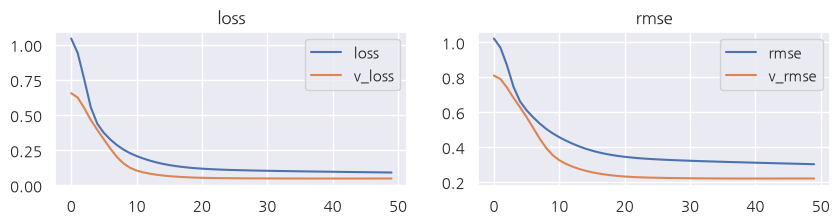

In [28]:
plt.figure(figsize=(10,2))
ax1 = plt.subplot(1,2,1)
ax1.plot(fit_res.history['loss']   ,   label="loss")
ax1.plot(fit_res.history['val_loss'],  label="v_loss")
ax1.legend()
ax1.set_title("loss")

ax2 = plt.subplot(1,2,2)
ax2.plot(fit_res.history['rmse']   ,   label="rmse")
ax2.plot(fit_res.history['val_rmse'],  label="v_rmse")
ax2.legend()
ax2.set_title("rmse")

plt.show()

## test 예측

In [29]:
pred = model.predict(X3_test)
print(pred, y3_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 237ms/step
[[0.6637871 0.6383656 0.6210247]] [[0.47871325 0.40164103 0.59954265]]


In [30]:
pred    = y_scaler.inverse_transform(pred)       #-------2D : 스케일링 된 예측값 점수 내기전 원복
y3_test = y_scaler.inverse_transform(y3_test)  #-------2D : 스케일링 된 정답값 점수 내기전 원복

In [31]:
print(pred, y3_test)

[[23.6017   19.246113 28.13151 ]] [[21.6 16.6 27.9]]


In [32]:
rmse = root_mean_squared_error(y3_test, pred)
print(f"RMSE : {rmse:.4f}")

RMSE : 1.6264
